# Week 2 — Exploratory Data Analysis (EDA)
**Project:** Food Delivery Data Analysis  |  **Notebook:** `02_exploratory_data_analysis.ipynb`

**Goal:** Understand how delivery duration varies with traffic, weather, distance, vehicle type and partner-related fields, using the cleaned dataset from Week 1.

**Rule followed throughout:** every number below is calculated in this notebook. Differences between groups are *associations*, not proof of cause and effect.

## 1. Setup and loading the cleaned dataset
**What / why:** Load `data/processed/cleaned_food_delivery.csv` (the Week 1 output) and standardise column names so the code is robust to naming differences. **Expectation:** about 45.6k rows, one row per delivery order. The raw file is not touched.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)

df = pd.read_csv("../data/processed/cleaned_food_delivery.csv")

# Standardise column names: lower case, snake_case ("Time_taken (min)" -> "time_taken_min")
df.columns = (df.columns.str.strip().str.lower()
              .str.replace(r"[^a-z0-9]+", "_", regex=True).str.strip("_"))
print("Shape:", df.shape)
print(list(df.columns))

Shape: (45584, 21)
['id', 'delivery_person_id', 'delivery_person_age', 'delivery_person_ratings', 'restaurant_latitude', 'restaurant_longitude', 'delivery_location_latitude', 'delivery_location_longitude', 'order_date', 'time_orderd', 'time_order_picked', 'weather_conditions', 'road_traffic_density', 'vehicle_condition', 'type_of_order', 'type_of_vehicle', 'multiple_deliveries', 'festival', 'city', 'time_taken_min', 'distance_km']


## 2. Identify and validate the key columns
**What / why:** Before calculating anything, confirm which column is the delivery duration and which fields exist. A missing field means that analysis must be skipped, not guessed. For distance, the Week 1 file may already contain `distance_km`; if not, it is computed from the coordinates (haversine formula, km) after removing placeholder coordinates (0 / 0.01).

In [2]:
TARGET = "time_taken_min"                       # delivery time in minutes (order -> doorstep)

# Distance: use the Week 1 column if present, otherwise derive it from coordinates
if "distance_km" not in df.columns:
    c = ["restaurant_latitude", "restaurant_longitude", "delivery_location_latitude", "delivery_location_longitude"]
    ok = (df[c[0]] > 0.1) & (df[c[1]] > 0.1) & (df[c[2]] > 0.1) & (df[c[3]] > 0.1)   # drop 0 / 0.01 placeholders
    lat1, lon1, lat2, lon2 = [np.radians(df[x].abs()) for x in c]
    a = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
    df["distance_km"] = np.where(ok, 6371*2*np.arcsin(np.sqrt(a)), np.nan)

wanted = {"traffic": "road_traffic_density", "weather": "weather_conditions", "vehicle": "type_of_vehicle",
          "distance": "distance_km", "age": "delivery_person_age", "ratings": "delivery_person_ratings",
          "multiple deliveries": "multiple_deliveries", "festival": "festival", "city": "city"}
avail = pd.DataFrame({"column": wanted.values(),
                      "present": [v in df.columns for v in wanted.values()],
                      "valid_rows": [df[v].notna().sum() if v in df.columns else 0 for v in wanted.values()],
                      "missing_rows": [df[v].isna().sum() if v in df.columns else None for v in wanted.values()]},
                     index=wanted.keys())
print("Target column present:", TARGET in df.columns, "| valid values:", df[TARGET].notna().sum(),
      "| non-positive values:", (df[TARGET] <= 0).sum())
display(avail)

Target column present: True | valid values: 45584 | non-positive values: 0


,column,present,valid_rows,missing_rows
traffic,road_traffic_density,True,44983,601
weather,weather_conditions,True,44968,616
vehicle,type_of_vehicle,True,45584,0
distance,distance_km,True,41944,3640
age,delivery_person_age,True,43730,1854
ratings,delivery_person_ratings,True,43623,1961
multiple deliveries,multiple_deliveries,True,44591,993
festival,festival,True,45356,228
city,city,True,44384,1200


**Result:** The target `time_taken_min` has 45,584 valid values and no non-positive values, so it can be used directly. All fields needed for the Week 2 comparisons are present. There is **no partner tenure / years-of-experience column**, so "experience" will be examined only through two *proxies* (age and rating) — these are not true experience measures. The table above shows how many rows each comparison column can actually use (missing rows are excluded from that comparison, not imputed).

## 3. Delivery-duration baseline
**What / why:** Establish the overall picture of delivery performance (centre, spread, shape) so later group differences can be judged against it. **Expectation:** typical delivery in the 20–35 minute range with some long deliveries.

Skewness: 0.486 | IQR fence: [-0.5, 51.5] | rows outside fence: 270
90th pct: 40 min | 95th pct: 44 min | deliveries > 40 min: 8.9%


,value
count,"45,584.00"
mean,26.29
median,26.00
minimum,10.00
maximum,54.00
25th percentile,19.00
75th percentile,32.00
std deviation,9.38


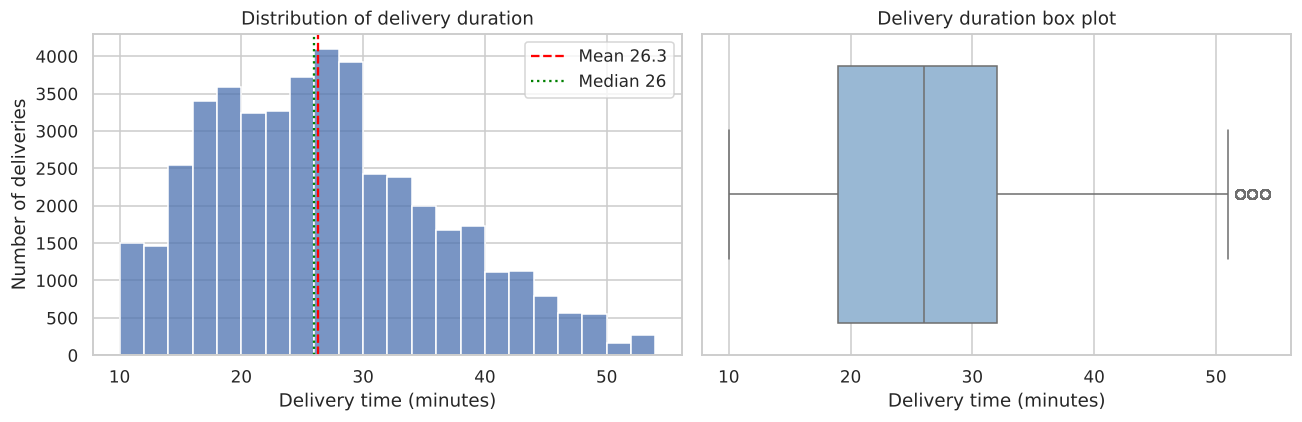

In [3]:
t = df[TARGET]
baseline = pd.DataFrame({"value": [t.count(), t.mean(), t.median(), t.min(), t.max(),
                                   t.quantile(.25), t.quantile(.75), t.std()]},
                        index=["count", "mean", "median", "minimum", "maximum", "25th percentile", "75th percentile", "std deviation"])
display(baseline)

# Shape and extreme values
skew = t.skew()
q1, q3 = t.quantile([.25, .75]); iqr = q3 - q1
lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
n_out = ((t < lo) | (t > hi)).sum()
p90, p95 = t.quantile([.90, .95])
share_over_40 = (t > 40).mean() * 100
print(f"Skewness: {skew:.3f} | IQR fence: [{lo:.1f}, {hi:.1f}] | rows outside fence: {n_out}")
print(f"90th pct: {p90:.0f} min | 95th pct: {p95:.0f} min | deliveries > 40 min: {share_over_40:.1f}%")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(t, bins=range(int(t.min()), int(t.max())+2, 2), ax=ax[0], color="#4C72B0")
ax[0].axvline(t.mean(), color="red", ls="--", label=f"Mean {t.mean():.1f}")
ax[0].axvline(t.median(), color="green", ls=":", label=f"Median {t.median():.0f}")
ax[0].set(title="Distribution of delivery duration", xlabel="Delivery time (minutes)", ylabel="Number of deliveries"); ax[0].legend()
sns.boxplot(x=t, ax=ax[1], color="#8FB8DE"); ax[1].set(title="Delivery duration box plot", xlabel="Delivery time (minutes)")
plt.tight_layout(); plt.show()

**Interpretation:** Across 45,584 deliveries the mean is 26.29 min and the median is 26 min, with a standard deviation of 9.38 min (range 10–54). The middle 50% of deliveries take 19–32 min. Skewness is 0.49, so the distribution is close to symmetric; the mean and median differ by only 0.29 min. By the 1.5×IQR rule, 270 deliveries are statistical outliers (the maximum of 54 min is outside the upper fence of 52 min). 8.9% of deliveries take longer than 40 minutes. These long deliveries are retained: they are plausible durations, not data errors.

## 4. Operational comparisons
A reusable helper reports **delivery count, mean and median duration** (plus standard deviation and each group's share of valid records) per category. Rows with a missing category are excluded from that table and reported separately.

In [4]:
def compare(col, order=None):
    valid = df.dropna(subset=[col])
    g = valid.groupby(col)[TARGET].agg(delivery_count="count", mean_min="mean", median_min="median", std_min="std")
    g["share_of_valid_%"] = g["delivery_count"] / g["delivery_count"].sum() * 100
    g = g.loc[order] if order else g.sort_values("mean_min")
    print(f"{col}: {len(valid):,} valid rows used, {df[col].isna().sum():,} missing rows excluded")
    return g

traffic_order = ["Low", "Medium", "High", "Jam"]
traffic_tbl = compare("road_traffic_density", traffic_order) if df["road_traffic_density"].str.istitle().all() else compare("road_traffic_density")
display(traffic_tbl)

road_traffic_density: 44,983 valid rows used, 601 missing rows excluded


,delivery_count,mean_min,median_min,std_min,share_of_valid_%
road_traffic_density,,,,,
Low,15476,21.27,20.00,6.80,34.40
Medium,10945,26.70,27.00,8.56,24.33
High,4423,27.24,27.00,8.40,9.83
Jam,14139,31.18,31.00,9.94,31.43


**Traffic result:** Mean duration rises from 21.27 min (Low, n=15,476) to 31.18 min (Jam, n=14,139) across the ordered categories — a gap of 9.91 min. Group sizes are all large, so the means are stable. Note that High (27.24 min) and Medium (26.70 min) are close to each other, and High is not much slower than Medium even though it is a 'heavier' label; section 5 shows that traffic categories also differ in typical delivery distance, which complicates the comparison.

In [5]:
weather_tbl = compare("weather_conditions")
display(weather_tbl)

weather_conditions: 44,968 valid rows used, 616 missing rows excluded


,delivery_count,mean_min,median_min,std_min,share_of_valid_%
weather_conditions,,,,,
Sunny,7282,21.86,20.00,8.33,16.19
Stormy,7584,25.87,26.00,8.47,16.87
Sandstorms,7494,25.88,26.00,8.62,16.67
Windy,7422,26.12,26.00,8.62,16.51
Fog,7653,28.91,28.00,10.13,17.02
Cloudy,7533,28.92,28.00,10.09,16.75


**Weather result:** Mean duration ranges from 21.86 min (Sunny) to 28.92 min (Cloudy), a spread of 7.06 min. The categories form roughly three tiers (see table); every category has at least 7,282 deliveries. Weather was recorded as a single label per order, and weather type may be correlated with city or season, so this is not a clean isolated effect.

In [6]:
vehicle_tbl = compare("type_of_vehicle")
display(vehicle_tbl)

type_of_vehicle: 45,584 valid rows used, 0 missing rows excluded


,delivery_count,mean_min,median_min,std_min,share_of_valid_%
type_of_vehicle,,,,,
electric_scooter,3814,24.47,24.00,8.61,8.37
scooter,15273,24.48,24.00,8.70,33.51
bicycle,68,26.43,26.00,9.26,0.15
motorcycle,26429,27.61,26.00,9.65,57.98


**Vehicle result:** Mean duration is lowest for electric_scooter (24.47 min, n=3,814) and highest for motorcycle (27.61 min, n=26,429). **Caution:** `bicycle` has only 68 deliveries (0.15% of records), so its figure is not reliable for comparison. Vehicle type may also be tied to distance, city and multiple-delivery load (checked in section 6).

## 5. Distance vs delivery duration
**What / why:** Distance is the most intuitive driver of delivery time. We calculate Pearson (linear) and Spearman (rank-based) correlation on rows where distance is valid, create the scatter plot, and also summarise duration by distance band. Rows with placeholder coordinates have no valid distance and are excluded (not imputed).

Valid rows: 41,944 | excluded (no valid distance): 3,640
Distance range: 1.47 - 20.97 km | mean 9.72 km
Pearson r = 0.320 | Spearman rho = 0.319 | r^2 = 0.103
Linear trend: duration = 21.09 + 0.54 * km


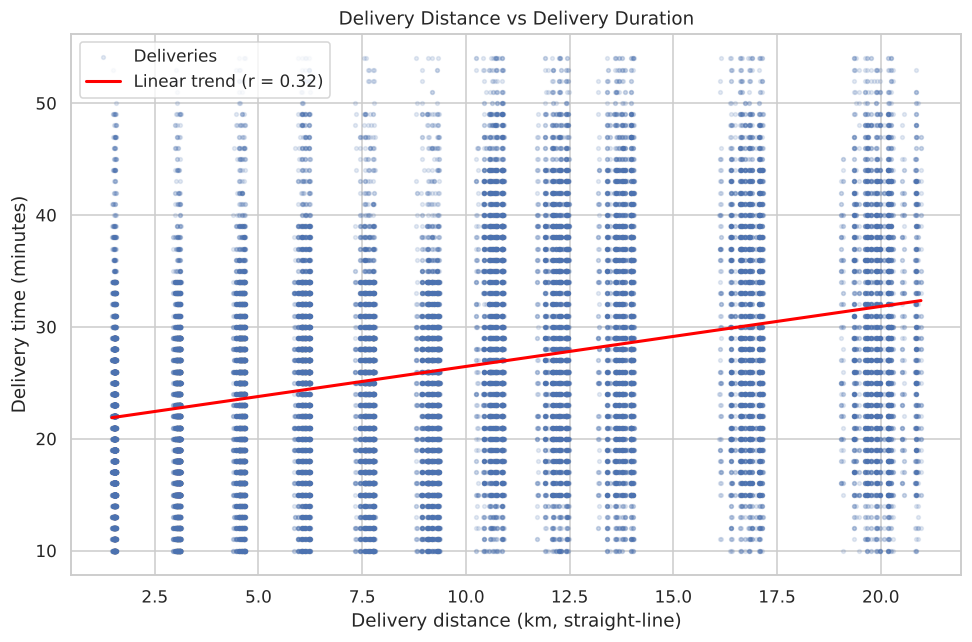

,delivery_count,mean_min,median_min
distance_band,,,
0-5 km,11300,22.19,21.00
5-10 km,11305,24.39,25.00
10-15 km,11293,29.83,29.00
15+ km,8046,29.86,29.00


,delivery_count,mean_km
road_traffic_density,,
High,4069,4.40
Jam,13039,12.04
Low,14199,8.15
Medium,10082,11.07


In [7]:
d = df.dropna(subset=["distance_km", TARGET])
pearson = d["distance_km"].corr(d[TARGET])
spearman = d["distance_km"].corr(d[TARGET], method="spearman")
slope, intercept = np.polyfit(d["distance_km"], d[TARGET], 1)
print(f"Valid rows: {len(d):,} | excluded (no valid distance): {len(df)-len(d):,}")
print(f"Distance range: {d.distance_km.min():.2f} - {d.distance_km.max():.2f} km | mean {d.distance_km.mean():.2f} km")
print(f"Pearson r = {pearson:.3f} | Spearman rho = {spearman:.3f} | r^2 = {pearson**2:.3f}")
print(f"Linear trend: duration = {intercept:.2f} + {slope:.2f} * km")

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(d["distance_km"], d[TARGET], s=6, alpha=0.15, color="#4C72B0", label="Deliveries")
xs = np.linspace(d.distance_km.min(), d.distance_km.max(), 100)
ax.plot(xs, intercept + slope*xs, color="red", lw=2, label=f"Linear trend (r = {pearson:.2f})")
ax.set(title="Delivery Distance vs Delivery Duration", xlabel="Delivery distance (km, straight-line)",
       ylabel="Delivery time (minutes)")
ax.legend(); plt.tight_layout()
fig.savefig("../visualizations/initial_distance_vs_duration.png", dpi=150, bbox_inches="tight")
plt.show()

bins = [0, 5, 10, 15, 25]; labels = ["0-5 km", "5-10 km", "10-15 km", "15+ km"]
d = d.assign(distance_band=pd.cut(d["distance_km"], bins=bins, labels=labels))
band_tbl = d.groupby("distance_band", observed=True)[TARGET].agg(delivery_count="count", mean_min="mean", median_min="median")
display(band_tbl)

# Does distance explain the traffic effect? Mean distance by traffic category
dist_by_traffic = d.groupby("road_traffic_density")["distance_km"].agg(delivery_count="count", mean_km="mean")
display(dist_by_traffic)

**Distance result:** Pearson r = 0.320 and Spearman ρ = 0.319 (n = 41,944), a weak-to-moderate positive association. The linear trend implies about 0.54 extra minutes per additional km, but r² = 0.103, so distance alone explains only about 10% of the variation in delivery time. The scatter shows a wide vertical spread at every distance, meaning other factors (traffic, weather, load, preparation time) matter a lot. Mean duration moves from 22.2 min in the shortest band to 29.9 min in the longest. The points form vertical stripes because distances in this dataset take a limited set of values (the coordinate offsets between restaurant and drop-off appear to be generated in fixed steps), so the plot shows discrete distance clusters rather than a continuous spread. Distances are *straight-line* estimates from coordinates, not road distances, which weakens the measured relationship. The bands show the increase is not uniform: the 10–15 km band (29.8 min) and the 15+ km band (29.9 min) are almost identical, so the relationship flattens beyond roughly 10 km. The last table shows mean distance differs a lot by traffic category (High = 4.40 km vs Jam = 12.04 km), so distance and traffic are entangled. Plot saved to `visualizations/initial_distance_vs_duration.png`.

## 6. Partner-related and additional fields
**Partner experience:** the dataset has no tenure column. We therefore examine two *proxies* — partner **age** and partner **rating** — and state clearly that they are not direct measures of experience. We also look at `multiple_deliveries`, `festival` and `city`, whose meanings are documented in the dataset README.

In [8]:
age = df.dropna(subset=["delivery_person_age"]).copy()
age["age_group"] = pd.cut(age["delivery_person_age"], [14, 24, 29, 34, 39, 60], labels=["15-24", "25-29", "30-34", "35-39", "40+"])
age_tbl = age.groupby("age_group", observed=True)[TARGET].agg(delivery_count="count", mean_min="mean", median_min="median")
r_age = age["delivery_person_age"].corr(age[TARGET])

rt = df.dropna(subset=["delivery_person_ratings"]).copy()
rt["rating_group"] = pd.cut(rt["delivery_person_ratings"], [0, 4.0, 4.5, 4.8, 5.0], labels=["<=4.0", "4.1-4.5", "4.6-4.8", "4.9-5.0"])
rating_tbl = rt.groupby("rating_group", observed=True)[TARGET].agg(delivery_count="count", mean_min="mean", median_min="median")
r_rating = rt["delivery_person_ratings"].corr(rt[TARGET])

print(f"Age: n={len(age):,}, correlation with duration = {r_age:.3f}")
display(age_tbl)
print(f"Ratings (valid 1-5 only): n={len(rt):,}, correlation with duration = {r_rating:.3f}")
display(rating_tbl)

Age: n=43,730, correlation with duration = 0.300
Ratings (valid 1-5 only): n=43,623, correlation with duration = -0.341


,delivery_count,mean_min,median_min
age_group,,,
15-24,10817,23.01,22.00
25-29,10853,22.98,22.00
30-34,10898,29.56,29.00
35-39,11109,29.51,29.00
40+,53,23.94,22.00


,delivery_count,mean_min,median_min
rating_group,,,
<=4.0,2444,35.91,35.00
4.1-4.5,8919,30.56,32.00
4.6-4.8,21224,24.25,24.00
4.9-5.0,11036,24.63,24.00


In [9]:
multi_tbl = compare("multiple_deliveries")
display(multi_tbl)
festival_tbl = compare("festival")
display(festival_tbl)
city_tbl = compare("city")
display(city_tbl)

multiple_deliveries: 44,591 valid rows used, 993 missing rows excluded
festival: 45,356 valid rows used, 228 missing rows excluded
city: 44,384 valid rows used, 1,200 missing rows excluded


,delivery_count,mean_min,median_min,std_min,share_of_valid_%
multiple_deliveries,,,,,
0.00,14094,22.88,22.00,8.77,31.61
1.00,28151,26.85,26.00,8.54,63.13
2.00,1985,40.45,40.00,4.92,4.45
3.00,361,47.82,48.00,3.48,0.81


,delivery_count,mean_min,median_min,std_min,share_of_valid_%
festival,,,,,
No,44460,25.98,25.00,9.01,98.02
Yes,896,45.52,45.00,4.00,1.98


,delivery_count,mean_min,median_min,std_min,share_of_valid_%
city,,,,,
Urban,10133,22.98,22.00,8.87,22.83
Metropolitian,34087,27.31,26.00,9.18,76.80
Semi-Urban,164,49.73,49.00,2.69,0.37


In [10]:
# Confounding checks: do the groups also differ in distance / load?
conf = pd.DataFrame({
    "mean_distance_km": d.groupby("type_of_vehicle")["distance_km"].mean(),
    "mean_multiple_deliveries": df.groupby("type_of_vehicle")["multiple_deliveries"].mean(),
    "delivery_count": df.groupby("type_of_vehicle").size()})
display(conf)

# Traffic x weather: median duration, to see whether the traffic effect holds inside each weather type
pivot = df.pivot_table(index="road_traffic_density", columns="weather_conditions", values=TARGET, aggfunc="median")
display(pivot.loc[[i for i in traffic_order if i in pivot.index]])

# Traffic effect within multiple_deliveries levels (mean duration)
load_traffic = (df.pivot_table(index="road_traffic_density", columns="multiple_deliveries", values=TARGET, aggfunc="mean")
                  .loc[[i for i in traffic_order if i in df.road_traffic_density.unique()]])
display(load_traffic)

,mean_distance_km,mean_multiple_deliveries,delivery_count
type_of_vehicle,,,
bicycle,9.44,0.76,68
electric_scooter,9.75,0.70,3814
motorcycle,9.69,0.78,26429
scooter,9.76,0.69,15273


weather_conditions,Cloudy,Fog,Sandstorms,Stormy,Sunny,Windy
road_traffic_density,,,,,,
Low,20.00,20.00,20.00,21.00,20.00,21.00
Medium,30.00,29.00,27.00,27.00,19.00,27.00
High,29.00,28.00,28.00,28.00,20.00,27.00
Jam,37.00,37.00,29.00,29.00,21.00,29.00


multiple_deliveries,0.0,1.0,2.0,3.0
road_traffic_density,,,,
Low,19.24,22.30,38.65,43.60
Medium,23.69,27.27,38.86,46.18
High,23.98,27.73,39.76,47.83
Jam,27.54,30.94,41.46,48.19


**Results:**
- **Age (proxy):** correlation with duration r = 0.300; the 30–39 age groups average about 29.5 min versus about 23.0 min for under-30s. The 40+ group has only 53 records. Older age is not expected to *cause* slower deliveries; it more likely stands in for other differences (e.g. assignment, area, vehicle).
- **Rating (proxy):** r = -0.341; group means run from 24.25 to 35.91 min. Rows with missing ratings, or ratings outside the valid 1–5 scale (set to missing during cleaning), are excluded.
- **Multiple deliveries:** mean duration goes from 22.88 min (value 0) to 47.82 min (value 3); the 3-delivery group has only 361 records.
- **Festival:** Yes = 45.52 min (n=896) vs No = 25.98 min (n=44,460).
- **City type:** Semi-Urban = 49.73 min but n = 164 only; Urban = 22.98 min, Metropolitian = 27.31 min.
- **Confounding checks:** vehicle groups have almost the same mean distance (9.44–9.76 km) and similar average delivery load (0.69–0.78), so distance and load do **not** explain the vehicle gap; the cause is unknown from these fields. In the traffic × weather table, under Low traffic the median is about 20–21 min for every weather type, and under Sunny weather it is about 19–21 min for every traffic level; the large increases appear for Cloudy/Fog combined with Medium-to-Jam traffic. In the traffic × load table, duration rises with the number of concurrent orders within every traffic level.

## 7. Visual exploration (quick checks)
**What / why:** Tables give exact numbers, but charts help me spot patterns, spread and odd groups faster. These are *exploratory* charts to guide my thinking; the polished, final visualisations are planned for Week 3. Bars show the **mean**, markers show the **median**, and the label under each category gives the group size (n) so small groups are not over-trusted.

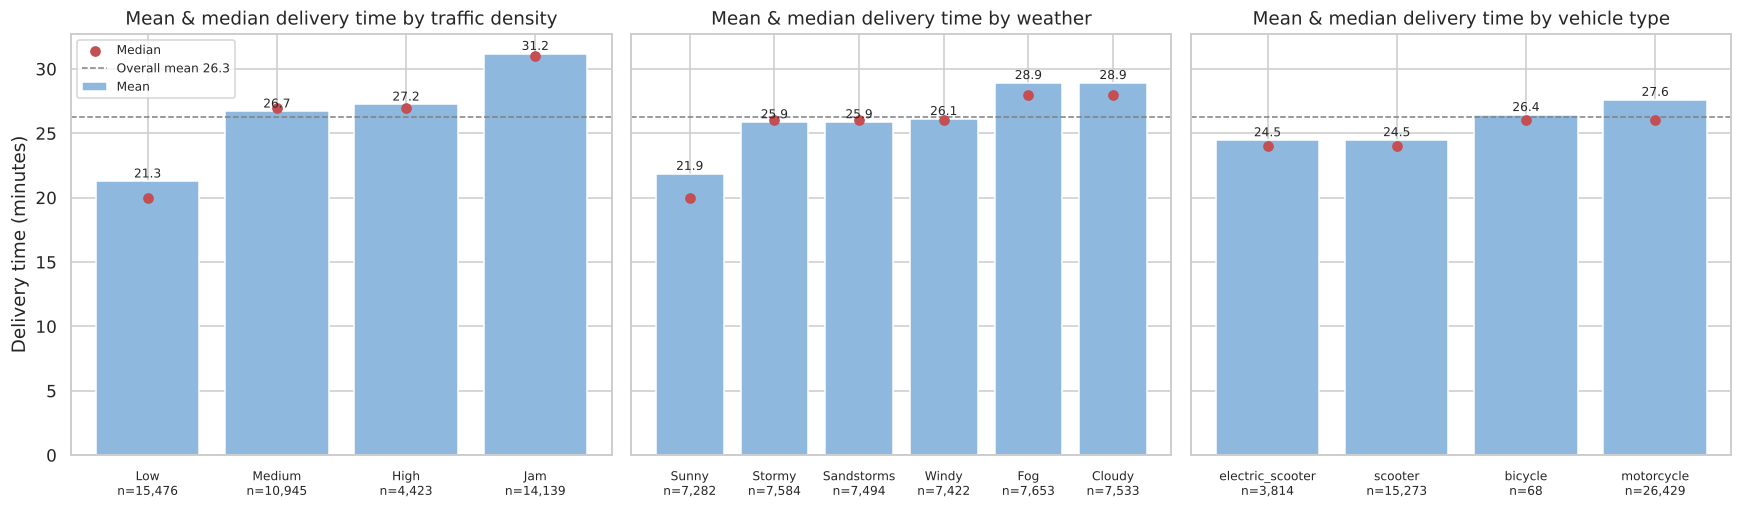

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
for ax, (tbl, title) in zip(axes, [(traffic_tbl, "Traffic density"), (weather_tbl, "Weather"), (vehicle_tbl, "Vehicle type")]):
    x = range(len(tbl))
    ax.bar(x, tbl["mean_min"], color="#8FB8DE", label="Mean")
    ax.scatter(x, tbl["median_min"], color="#C44E52", zorder=3, label="Median")
    ax.axhline(t.mean(), color="grey", ls="--", lw=1, label=f"Overall mean {t.mean():.1f}")
    ax.set_xticks(list(x)); ax.set_xticklabels([f"{i}\nn={int(n):,}" for i, n in zip(tbl.index, tbl["delivery_count"])], fontsize=8)
    for i, v in enumerate(tbl["mean_min"]): ax.text(i, v + 0.3, f"{v:.1f}", ha="center", fontsize=8)
    ax.set_title(f"Mean & median delivery time by {title.lower()}")
axes[0].set_ylabel("Delivery time (minutes)"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

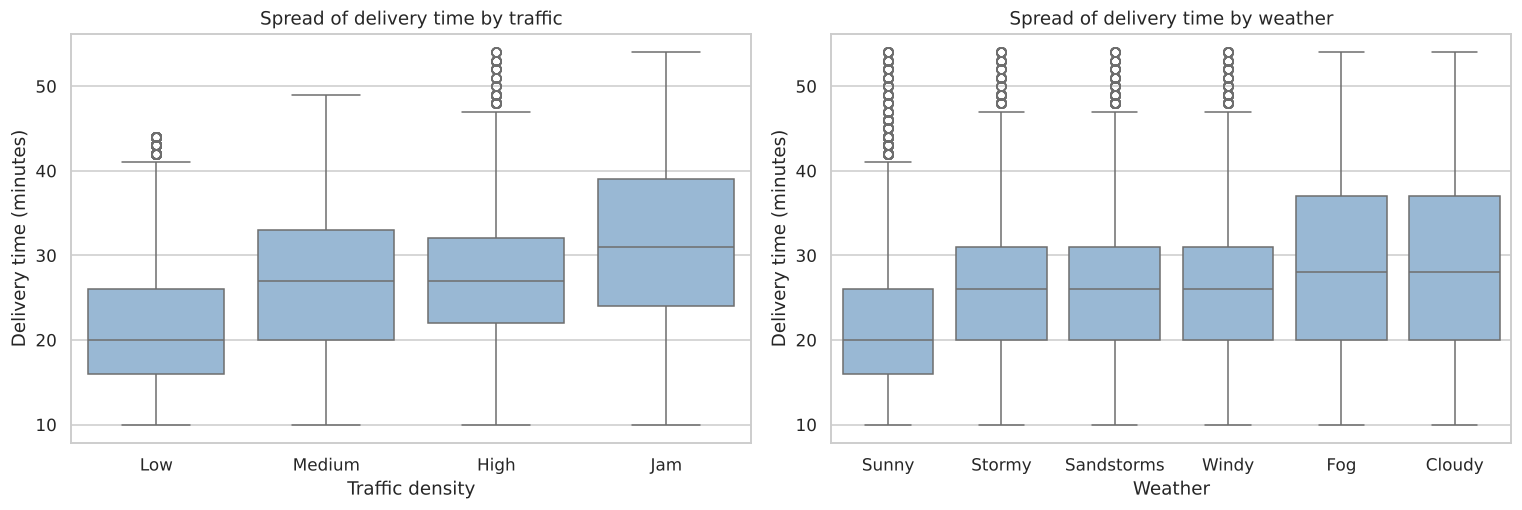

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.boxplot(data=df.dropna(subset=["road_traffic_density"]), x="road_traffic_density", y=TARGET, order=traffic_order, color="#8FB8DE", ax=axes[0])
axes[0].set(title="Spread of delivery time by traffic", xlabel="Traffic density", ylabel="Delivery time (minutes)")
sns.boxplot(data=df.dropna(subset=["weather_conditions"]), x="weather_conditions", y=TARGET, order=weather_tbl.index, color="#8FB8DE", ax=axes[1])
axes[1].set(title="Spread of delivery time by weather", xlabel="Weather", ylabel="Delivery time (minutes)")
plt.tight_layout(); plt.show()

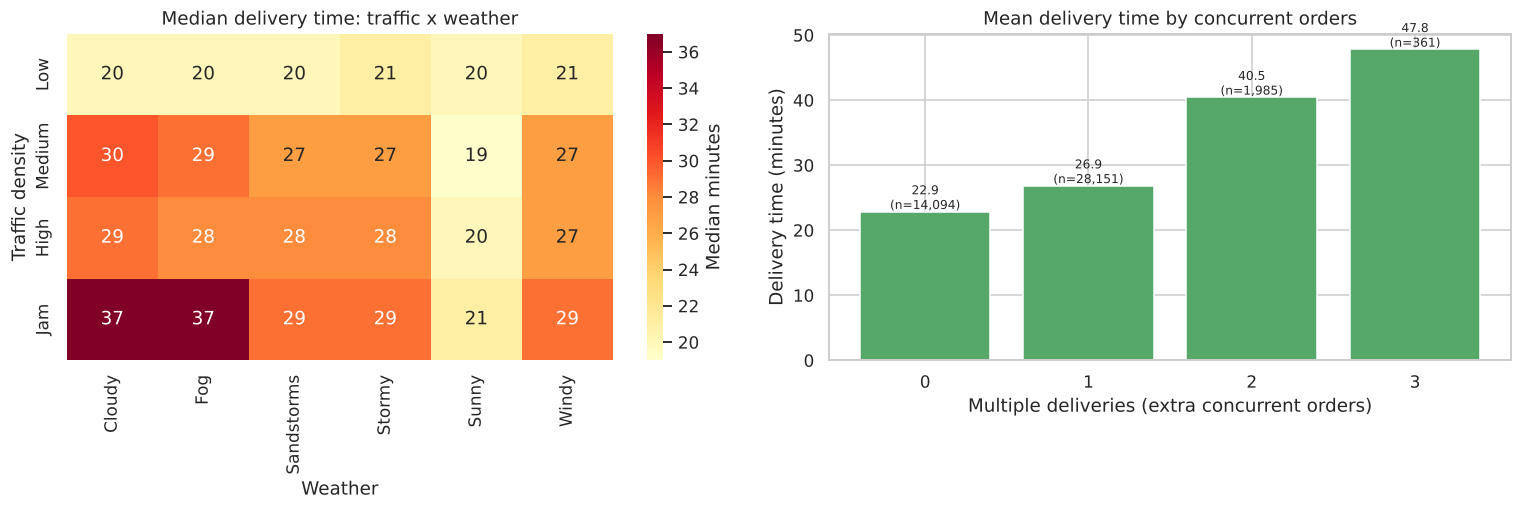

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.heatmap(pivot.loc[traffic_order], annot=True, fmt=".0f", cmap="YlOrRd", ax=axes[0], cbar_kws={"label": "Median minutes"})
axes[0].set(title="Median delivery time: traffic x weather", xlabel="Weather", ylabel="Traffic density")
mt = multi_tbl.reset_index()
axes[1].bar(mt["multiple_deliveries"].astype(int).astype(str), mt["mean_min"], color="#55A868")
for i, (m, n) in enumerate(zip(mt["mean_min"], mt["delivery_count"])): axes[1].text(i, m + 0.4, f"{m:.1f}\n(n={int(n):,})", ha="center", fontsize=8)
axes[1].set(title="Mean delivery time by concurrent orders", xlabel="Multiple deliveries (extra concurrent orders)", ylabel="Delivery time (minutes)")
plt.tight_layout(); plt.show()

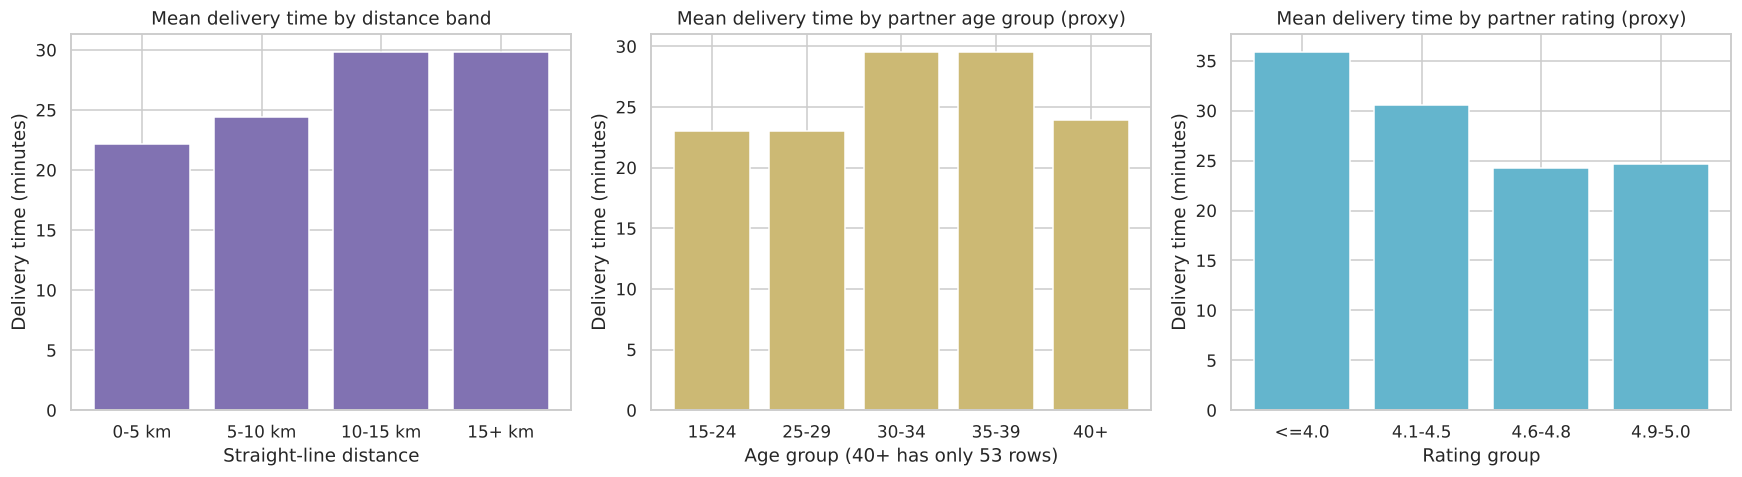

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].bar(band_tbl.index.astype(str), band_tbl["mean_min"], color="#8172B2")
axes[0].set(title="Mean delivery time by distance band", xlabel="Straight-line distance", ylabel="Delivery time (minutes)")
axes[1].bar(age_tbl.index.astype(str), age_tbl["mean_min"], color="#CCB974")
axes[1].set(title="Mean delivery time by partner age group (proxy)", xlabel="Age group (40+ has only 53 rows)", ylabel="Delivery time (minutes)")
axes[2].bar(rating_tbl.index.astype(str), rating_tbl["mean_min"], color="#64B5CD")
axes[2].set(title="Mean delivery time by partner rating (proxy)", xlabel="Rating group", ylabel="Delivery time (minutes)")
plt.tight_layout(); plt.show()

**What the charts add (what I see, not proven causes):**
- The traffic/weather/vehicle bars confirm the table gaps, and the group-size labels show that only `bicycle` is too small to trust.
- The box plots show that Jam, Fog and Cloudy have both a higher centre and a wider spread (std 9.9 min for Jam vs 6.8 for Low), so they are less predictable, not just slower.
- The heatmap shows that weather matters mostly when traffic is Medium or heavier: the Sunny column stays near 19–21 min, while Cloudy/Fog in Jam reach 37 min.
- The concurrent-order bars show the biggest visible step (from 26.9 to 40.5 min between 1 and 2 orders), but the 2 and 3 groups are small.
- The age, rating and distance-band charts show these fields track duration, but the shapes are step-like rather than smooth, so I treat them as rough patterns only.

## 8. Key observations
Each observation states the question, metric, result, comparison, group size and a cautious interpretation. *"Data shows"* = calculated fact; *"Interpretation"* = possible explanation, not proven.

### Observation 1 — Overall delivery performance
- **Question:** What is a typical delivery time and how variable is it?
- **Metric / result:** mean 26.29 min, median 26 min, SD 9.38, IQR 19–32 (n = 45,584).
- **Data shows:** mean ≈ median (skew 0.49); 8.9% of orders exceed 40 min.
- **Interpretation:** Performance is fairly consistent around ~26 min; the long-tail orders are the improvement opportunity.

### Observation 2 — Traffic density and delivery time
- **Question:** Do deliveries take longer in heavier traffic?
- **Metric / result:** mean duration Low = 21.27 min (n=15,476), Medium = 26.70 (n=10,945), High = 27.24 (n=4,423), Jam = 31.18 (n=14,139).
- **Comparison:** Jam is 9.91 min (47%) slower than Low traffic.
- **Interpretation:** Heavier traffic is associated with longer deliveries (Low is clearly fastest, Jam slowest). Traffic categories also differ in typical distance (mean 8.1 km Low, 4.4 km High, 12.0 km Jam), which may explain why High is only slightly slower than Medium. This is an association, not proof of causation.

### Observation 3 — Weather and delivery time
- **Question:** Which weather conditions are linked to the slowest deliveries?
- **Metric / result:** slowest = Cloudy (28.92 min, n=7,533); fastest = Sunny (21.86 min, n=7,282).
- **Comparison:** gap of 7.06 min (32%).
- **Data shows (breakdown):** at Low traffic the median is about 20–21 min in all weather types; under Sunny weather it is about 19–21 min at all traffic levels. The gap appears mainly for Cloudy/Fog combined with Medium-to-Jam traffic (median 28–37 min).
- **Interpretation:** Weather and traffic seem to interact rather than act independently. Weather may also be confounded with location and season, so no causal claim is made.

### Observation 4 — Distance has a real but limited relationship with duration
- **Question:** How strongly does distance relate to delivery time?
- **Metric / result:** Pearson r = 0.320, Spearman ρ = 0.319, n = 41,944; ≈ 0.54 min per km.
- **Comparison:** shortest band (0-5 km) mean 22.2 min vs longest (15+ km) 29.9 min.
- **Interpretation:** Longer distance goes with longer time, but r² = 0.10 means most variation comes from other factors. The increase flattens beyond ~10 km (29.8 vs 29.9 min for the two longest bands). Straight-line distance is only an approximation of the real route.

### Observation 5 — Vehicle type
- **Question:** Do some vehicles deliver faster than others?
- **Metric / result:** motorcycle 27.61 min (n=26,429), scooter 24.48 (n=15,273), electric_scooter 24.47 (n=3,814); bicycle 26.43 (n=68, too small).
- **Comparison:** motorcycles are 3.13 min slower on average than scooters.
- **Data shows (checks):** mean distance is similar across vehicles (motorcycle 9.69 km vs scooter 9.76 km) and so is average load (0.78 vs 0.69).
- **Interpretation:** Distance and load do not explain the gap; other unmeasured factors (area, partner, vehicle condition) may. The bicycle result (n=68) is too small to compare.

### Observation 6 — Multiple concurrent deliveries
- **Question:** Does carrying more than one order slow delivery?
- **Metric / result:** mean duration for 0 / 1 / 2 / 3 concurrent orders = 22.88 / 26.85 / 40.45 / 47.82 min (n = 14,094 / 28,151 / 1,985 / 361).
- **Comparison:** 3 concurrent orders take 24.94 min longer than 0.
- **Data shows (breakdown):** the increase appears at every traffic level (e.g. Low traffic: 19.2 → 43.6 min; Jam: 27.5 → 48.2 min).
- **Interpretation:** Carrying more concurrent orders is strongly associated with longer delivery time, independent of traffic level; the 2 and 3 groups are small (1,985 and 361) and their low spread (SD 4.9 and 3.5 min) suggests they may follow a distinct process, so confirm before acting on it.

### Observation 7 — Festival periods
- **Question:** Are festival-day orders slower?
- **Metric / result:** Festival = Yes 45.52 min (n=896) vs No 25.98 min (n=44,460).
- **Comparison:** difference of 19.53 min.
- **Interpretation:** A large gap, but only 896 festival records; demand surges and traffic during festivals are possible explanations, to be tested with more data.

### Observation 8 — Partner age and rating (proxies, not experience)
- **Question:** Do partner age or rating relate to delivery time?
- **Metric / result:** correlation with duration: age r = 0.300 (n=43,730), rating r = -0.341 (n=43,623). Partners rated ≤4.0 average 35.9 min (n=2,444) versus 24.3 min for 4.6–4.8 (n=21,224).
- **Comparison:** these correlations are of similar size to the distance correlation (0.32), i.e. moderate.
- **Interpretation:** Lower-rated partners are associated with slower deliveries (customers may rate slow deliveries lower, so direction is unclear), and older partners with slower deliveries, which is counter-intuitive if age meant experience. Neither field measures experience, so no conclusion about partner experience can be drawn.

## 9. Limitations and assumptions
- **Association ≠ causation:** all group differences are observational; traffic, weather, city, vehicle and delivery load overlap with each other.
- **Distance** is straight-line (haversine) from coordinates, not road distance; rows with placeholder coordinates (about 8% of records) have no distance and were excluded from distance analysis only.
- **No tenure column:** partner experience cannot be measured directly; age and rating are only proxies.
- **Small groups:** `bicycle`, `Semi-Urban`, `Festival = Yes` and 3 concurrent deliveries have small samples — treat comparisons involving them cautiously.
- **Missing categories** (traffic, weather, city, etc.) were excluded per comparison, not imputed.
- **Time-of-day / order-to-pickup analysis** was out of scope for Week 2.

**Next (Week 3):** build the five finalised visualisations from these findings.